In [20]:
import shap
import pandas as pd
import xgboost as xgb
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
import numpy as np

In [2]:
df = pd.read_csv('../../../datasets/balanceados/dataset_fluxo_balanceado.csv')
dropar = ['Average Packet Size', 'Packet Length Std', 'Packet Length Mean', 'Total Length of Fwd Packets',
           'Bwd Packets/s', 'Packet Length Variance', 'Flow Bytes/s', 'Subflow Fwd Bytes', 'Total Backward Packets',
           'Subflow Bwd Packets']
df.drop(columns=dropar, inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Length of Bwd Packets  104802 non-null  float64
 2   Flow Packets/s               104802 non-null  float64
 3   Flow IAT Mean                104802 non-null  float64
 4   Flow IAT Std                 104802 non-null  float64
 5   Flow IAT Max                 104802 non-null  float64
 6   Flow IAT Min                 104802 non-null  float64
 7   Fwd Packets/s                104802 non-null  float64
 8   Down/Up Ratio                104802 non-null  float64
 9   Subflow Fwd Packets          104802 non-null  int64  
 10  Subflow Bwd Bytes            104802 non-null  int64  
 11  Label                        104802 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 9.6 MB


In [3]:
x=df.drop(columns=['Label'])
y=df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)

DT

In [4]:
modelo_dt = tree.DecisionTreeClassifier(random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
matriz_dt1 = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    matriz_dt1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9594
Acurácia:  95.7159
Precisão:  95.9991
Recall:    95.6861
F1-Score:  95.7070

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)                91.9%                 8.1%
Real: 1 (Ataque)                0.53%               99.47%


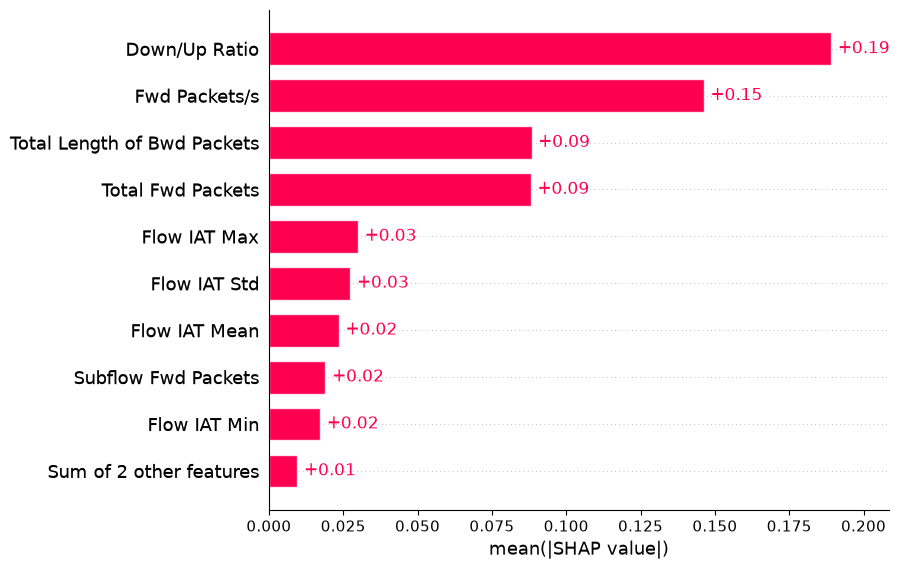

In [5]:
explainer_dt = shap.TreeExplainer(modelo_dt)
shap_values_dt = explainer_dt(amostra_500)

shap.plots.bar(shap_values_dt[:, :, 1])

RF

In [6]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9594
Acurácia:  95.8160
Precisão:  96.0938
Recall:    95.7866
F1-Score:  95.8076

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               92.05%                7.95%
Real: 1 (Ataque)                0.47%               99.53%


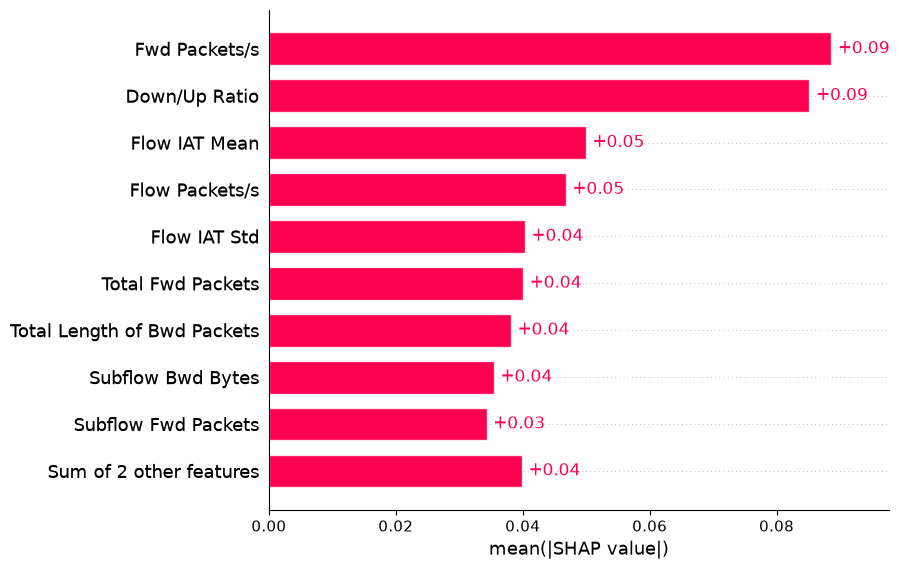

In [7]:
explainer_rf = shap.TreeExplainer(modelo_rf)
shap_values_rf = explainer_rf(amostra_500)        

shap.plots.bar(shap_values_rf[:, :, 1])

XGB

In [8]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9569
Acurácia:  95.8447
Precisão:  96.1117
Recall:    95.8158
F1-Score:  95.8365

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               92.15%                7.85%
Real: 1 (Ataque)                0.52%               99.48%


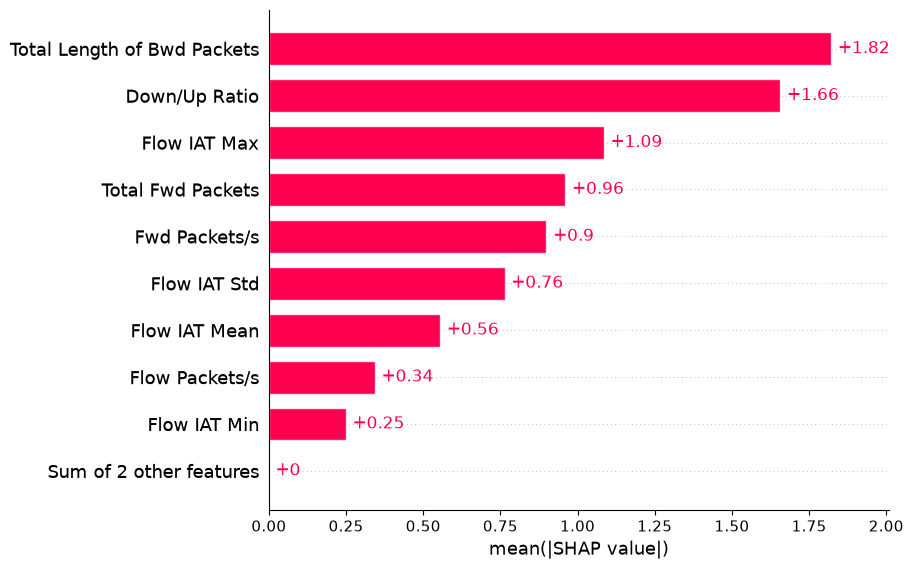

In [9]:
explainer_xgb = shap.TreeExplainer(modelo_xgb)
shap_values_xgb = explainer_xgb(amostra_500)

shap.plots.bar(shap_values_xgb)

SVM

In [10]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.8808
Acurácia:  88.2925
Precisão:  90.0215
Recall:    88.2111
F1-Score:  88.1482

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               77.87%               22.13%
Real: 1 (Ataque)                1.45%               98.55%


Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


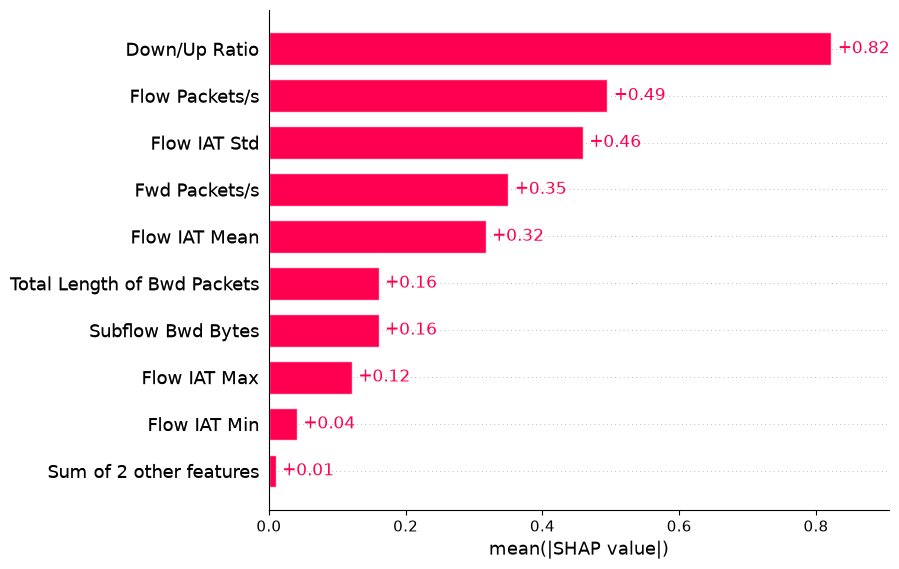

In [11]:
explainer_svm = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values_svm = explainer_svm(amostra_500)

shap.plots.bar(shap_values_svm)    

KNN

In [12]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9561
Acurácia:  95.6634%
Precisão:  95.9414%
Recall:    95.6338%
F1-Score:  95.6546%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               91.88%                8.12%
Real: 1 (Ataque)                0.62%               99.38%


PermutationExplainer explainer: 101it [09:48,  5.89s/it]                         


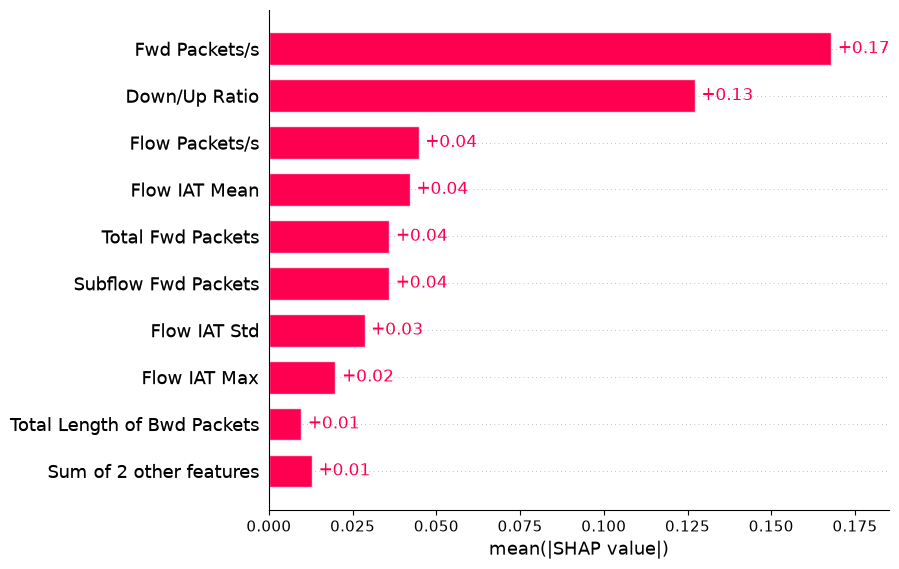

In [13]:
explainer_knn = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_knn = explainer_knn(amostra_100)

shap.plots.bar(shap_values_knn[:,:, 1])

MLP

In [18]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9488
Acurácia:  95.0766
Precisão:  95.3749
Recall:    95.0457
F1-Score:  95.0658

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               91.12%                8.88%
Real: 1 (Ataque)                1.03%               98.97%


c:\Users\jvesc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


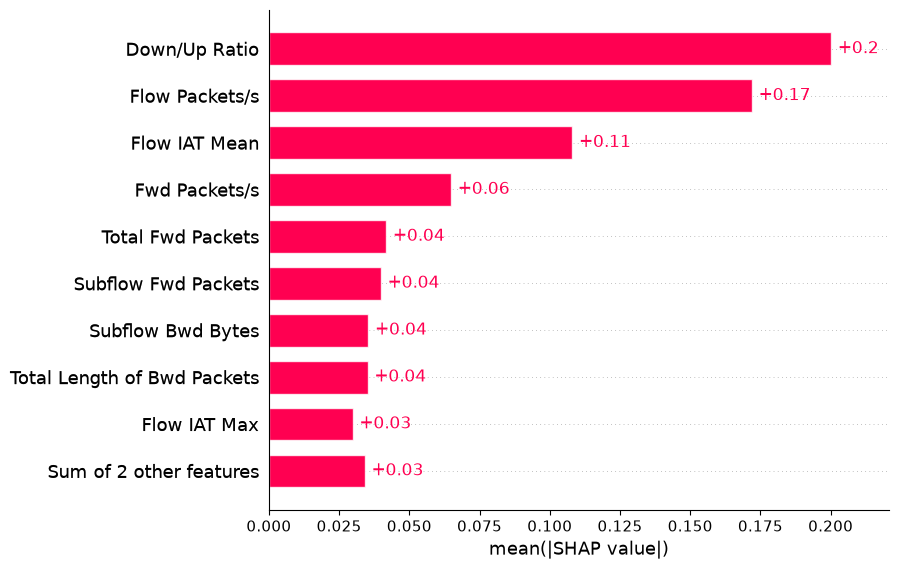

In [19]:
explainer_mlp = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_mlp = explainer_mlp(amostra_100)

shap.plots.bar(shap_values_mlp[:, :, 1])

CONSENSO

In [25]:
# Monta o df com o valor exato plotado nos gráficos de barra (Média do |SHAP|)
df = pd.DataFrame({
    'DT':  np.abs(shap_values_dt.values[:, :, 1]).mean(axis=0),
    'RF':  np.abs(shap_values_rf.values[:, :, 1]).mean(axis=0),
    'XGB': np.abs(shap_values_xgb.values).mean(axis=0),
    'SVM': np.abs(shap_values_svm.values).mean(axis=0),
    'KNN': np.abs(shap_values_knn.values[:, :, 1]).mean(axis=0),
    'MLP': np.abs(shap_values_mlp.values[:, :, 1]).mean(axis=0)
}, index=x.columns)

# 1. Normalização SHAP por modelo
shap_norm = df.div(df.sum(axis=0), axis=1)

# 2. Frequência de ocorrência
frequencia = (df > 0).sum(axis=1)

# 3. Média SHAP normalizada nas ocorrências
shap_medio = shap_norm.sum(axis=1) / frequencia.replace(0, float("nan"))

# 4. Score de consenso
consenso = shap_medio * (frequencia / df.shape[1])

# 5. Ranking final
ranking = pd.DataFrame({
    "Frequencia": frequencia,
    "SHAP_Medio": shap_medio*100,
    "Consenso": consenso*100
    
}).sort_values("Consenso", ascending=False)

print("\n--- RANKING FINAL DE CONSENSO ---")
print(ranking)


--- RANKING FINAL DE CONSENSO ---
                             Frequencia  SHAP_Medio   Consenso
Down/Up Ratio                         6   24.185896  24.185896
Fwd Packets/s                         6   17.318373  17.318373
Flow Packets/s                        6   10.474664  10.474664
Total Length of Bwd Packets           6    9.209442   9.209442
Flow IAT Mean                         6    8.893821   8.893821
Total Fwd Packets                     6    7.643167   7.643167
Flow IAT Std                          6    7.622633   7.622633
Flow IAT Max                          6    5.993482   5.993482
Subflow Fwd Packets                   5    4.421658   3.684715
Subflow Bwd Bytes                     5    3.814712   3.178926
Flow IAT Min                          6    1.794881   1.794881
